In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "fitness_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

Dataset shape: (15000, 25)


In [2]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe().T)

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(10))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 25 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   User_ID                             15000 non-null  object 
 1   Age                                 15000 non-null  int64  
 2   Gender                              15000 non-null  object 
 3   Height_cm                           15000 non-null  float64
 4   Weight_kg                           15000 non-null  float64
 5   BMI                                 15000 non-null  float64
 6   Resting_Heart_Rate                  15000 non-null  int64  
 7   Blood_Pressure_Systolic             15000 non-null  int64  
 8   Blood_Pressure_Diastolic            15000 non-null  int64  
 9   Daily_Steps                         15000 non-null  int64  
 10  Sleep_Hours                         14824 non-null  float64
 11  Water_Intake_Liters 

,count,mean,std,min,25%,50%,75%,max
Age,15000.0,36.371533,12.098366,18.0,27.000,36.00,44.00,75.00
Height_cm,15000.0,168.529993,9.353814,145.0,161.600,168.20,175.30,200.00
Weight_kg,15000.0,69.976827,14.411565,42.0,59.500,69.10,79.20,139.20
BMI,15000.0,24.558830,4.213966,16.5,21.570,24.51,27.44,41.99
Resting_Heart_Rate,15000.0,71.834333,8.575006,42.0,66.000,72.00,78.00,101.00
Blood_Pressure_Systolic,15000.0,121.303267,11.893850,85.0,113.000,121.00,129.00,172.00
Blood_Pressure_Diastolic,15000.0,67.454600,7.032214,50.0,63.000,68.00,72.00,95.00
Daily_Steps,15000.0,8488.054867,2909.039411,300.0,6528.000,8538.50,10490.25,22446.00
Sleep_Hours,14824.0,7.028616,0.997418,3.5,6.400,7.00,7.70,10.50
Water_Intake_Liters,14840.0,2.021055,0.494826,0.4,1.690,2.02,2.35,4.33



Missing values:


Sleep_Hours                 176
Water_Intake_Liters         160
Protein_Grams               108
Workout_Type                 91
Weight_kg                     0
Age                           0
Gender                        0
Height_cm                     0
User_ID                       0
Blood_Pressure_Diastolic      0
dtype: int64

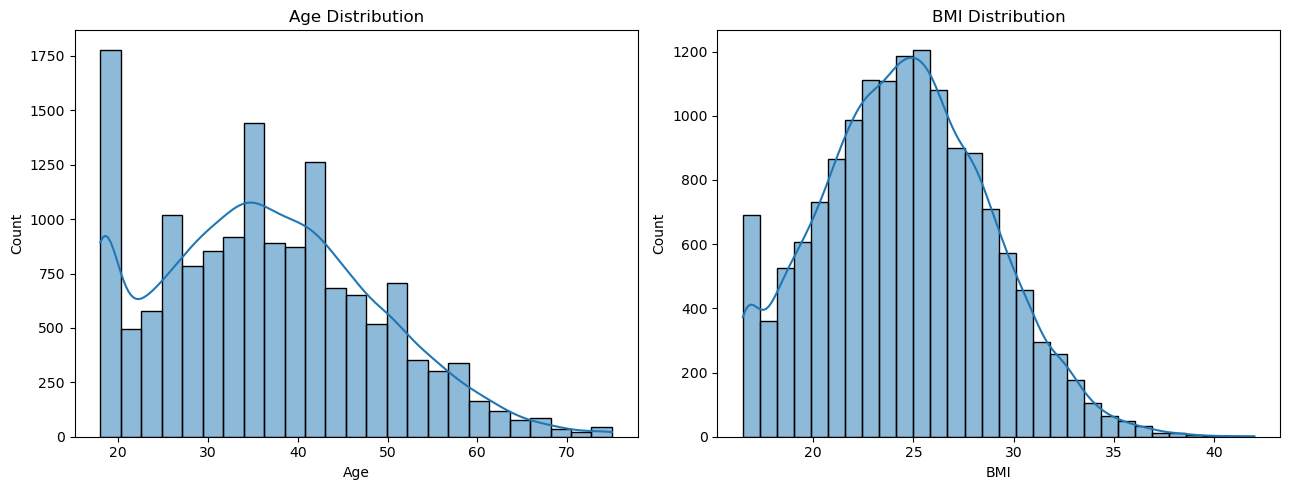

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(data=df, x="Age", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.histplot(data=df, x="BMI", bins=30, kde=True, ax=axes[1])
axes[1].set_title("BMI Distribution")

plt.tight_layout()
plt.show()

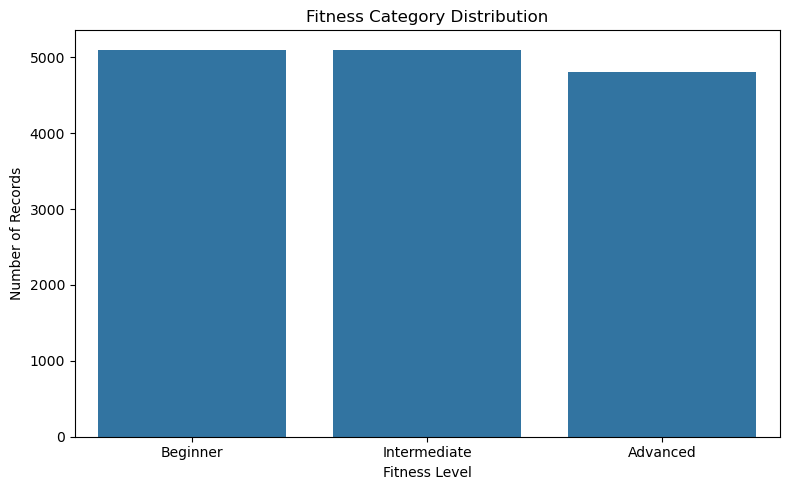

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Fitness_Level",
    order=["Beginner", "Intermediate", "Advanced"]
)

plt.title("Fitness Category Distribution")
plt.xlabel("Fitness Level")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import numpy as np

# Separate features and target
X = df.drop(columns=["Fitness_Level", "User_ID"])
y = df["Fitness_Level"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in features:")
print(X.isna().sum()[X.isna().sum() > 0])

print("\nTarget missing values:", y.isna().sum())

Features shape: (15000, 23)
Target shape: (15000,)

Missing values in features:
Sleep_Hours            176
Water_Intake_Liters    160
Workout_Type            91
Protein_Grams          108
dtype: int64

Target missing values: 0


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training records: 12000
Testing records: 3000
Numeric features: 19
Categorical features: 4


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import clone

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

    trained_models[name] = pipeline
    print(f"Finished training: {name}")

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Finished training: Logistic Regression
Finished training: Decision Tree
Finished training: Random Forest
Finished training: Gradient Boosting
Finished training: KNN


,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.8840,0.8851,0.8840,0.8844
1,Logistic Regression,0.8797,0.8801,0.8797,0.8799
2,Random Forest,0.8770,0.8787,0.8770,0.8776
3,Decision Tree,0.8190,0.8182,0.8190,0.8185
4,KNN,0.7017,0.7012,0.7017,0.7014


In [8]:
display(results_df)

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Accuracy:", round(results_df.iloc[0]["Accuracy"], 4))
print("F1 Score:", round(results_df.iloc[0]["F1 Score"], 4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Gradient Boosting,0.884000,0.885060,0.884000,0.884426
1,Logistic Regression,0.879667,0.880130,0.879667,0.879874
2,Random Forest,0.877000,0.878700,0.877000,0.877614
3,Decision Tree,0.819000,0.818177,0.819000,0.818546
4,KNN,0.701667,0.701238,0.701667,0.701394


Best Model: Gradient Boosting
Accuracy: 0.884
F1 Score: 0.8844


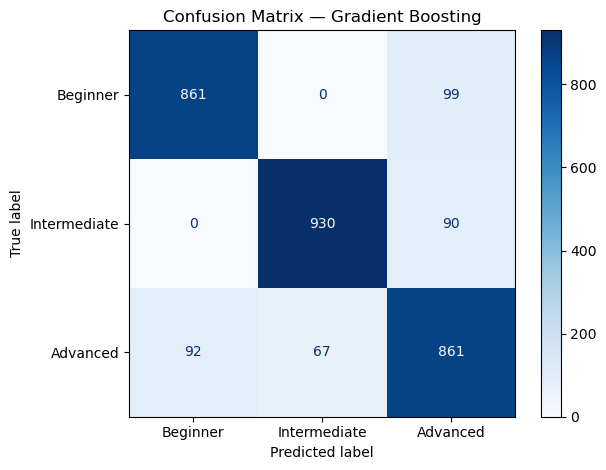

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["Beginner", "Intermediate", "Advanced"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path
import joblib

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "fitness_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)

Model saved successfully!
Saved location: C:\Users\User\FitPredict_AI\models\fitness_model.joblib


In [11]:
from pathlib import Path
import joblib

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

joblib.dump(best_model, model_dir / "fitness_model.joblib")

print("Best model:", best_model_name)
print("Model saved:", model_dir / "fitness_model.joblib")

Best model: Gradient Boosting
Model saved: C:\Users\User\FitPredict_AI\models\fitness_model.joblib


In [12]:
import sklearn
print("Notebook scikit-learn version:", sklearn.__version__)

Notebook scikit-learn version: 1.6.1


In [13]:
import sklearn
import joblib
from pathlib import Path

print("Scikit-learn version:", sklearn.__version__)

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

model_dir = PROJECT_ROOT / "models"
model_dir.mkdir(parents=True, exist_ok=True)

best_model = trained_models["Gradient Boosting"]

joblib.dump(
    best_model,
    model_dir / "fitness_model.joblib"
)

print("Model saved successfully!")

Scikit-learn version: 1.6.1
Model saved successfully!


In [14]:
import joblib

model_path = PROJECT_ROOT / "models" / "fitness_model.joblib"
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [15]:
import sys
import sklearn

print("Python:", sys.version)
print("Python path:", sys.executable)
print("Scikit-learn:", sklearn.__version__)

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Python path: C:\Users\User\anaconda3\python.exe
Scikit-learn: 1.6.1


In [16]:

print(df["Workout_Consistency"].describe())
print("\nSample values:")
print(df["Workout_Consistency"].head(10).tolist())


count    15000.000000
mean        52.413667
std         22.549149
min          0.000000
25%         36.475000
50%         53.000000
75%         68.800000
max        100.000000
Name: Workout_Consistency, dtype: float64

Sample values:
[77.3, 37.0, 42.6, 35.8, 56.4, 75.4, 48.5, 48.8, 69.6, 63.1]


In [17]:

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nWorkout Consistency:")
print(df["Workout_Consistency"].describe())

print("\nSample values:")
print(df["Workout_Consistency"].head(10).tolist())

print("\nColumn names:")
print(df.columns.tolist())


Dataset shape: (15000, 25)

Missing values:
535

Duplicate rows:
0

Workout Consistency:
count    15000.000000
mean        52.413667
std         22.549149
min          0.000000
25%         36.475000
50%         53.000000
75%         68.800000
max        100.000000
Name: Workout_Consistency, dtype: float64

Sample values:
[77.3, 37.0, 42.6, 35.8, 56.4, 75.4, 48.5, 48.8, 69.6, 63.1]

Column names:
['User_ID', 'Age', 'Gender', 'Height_cm', 'Weight_kg', 'BMI', 'Resting_Heart_Rate', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Daily_Steps', 'Sleep_Hours', 'Water_Intake_Liters', 'Exercise_Days_Per_Week', 'Exercise_Hours_Per_Week', 'Exercise_Intensity', 'Workout_Type', 'Cardio_Minutes_Per_Week', 'Strength_Training_Minutes_Per_Week', 'Daily_Calorie_Intake', 'Protein_Grams', 'Carbohydrates_Grams', 'Fat_Grams', 'Workout_Consistency', 'Fitness_Level', 'Fitness_Goal']


In [18]:

print("Missing values by column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTarget distribution:")
print(df["Fitness_Level"].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    (df["Fitness_Level"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

print("\nFitness Goal distribution:")
print(df["Fitness_Goal"].value_counts(dropna=False))


Missing values by column:
Sleep_Hours            176
Water_Intake_Liters    160
Workout_Type            91
Protein_Grams          108
dtype: int64

Target distribution:
Fitness_Level
Beginner        5100
Intermediate    5100
Advanced        4800
Name: count, dtype: int64

Target percentages:
Fitness_Level
Beginner        34.0
Intermediate    34.0
Advanced        32.0
Name: proportion, dtype: float64

Fitness Goal distribution:
Fitness_Goal
General Fitness      4874
Improve Endurance    3894
Build Muscle         3262
Weight Management    2970
Name: count, dtype: int64


In [19]:

print("Missing values before preprocessing:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nData types:")
print(df.dtypes)


Missing values before preprocessing:
Sleep_Hours            176
Water_Intake_Liters    160
Workout_Type            91
Protein_Grams          108
dtype: int64

Total missing values: 535

Data types:
User_ID                                object
Age                                     int64
Gender                                 object
Height_cm                             float64
Weight_kg                             float64
BMI                                   float64
Resting_Heart_Rate                      int64
Blood_Pressure_Systolic                 int64
Blood_Pressure_Diastolic                int64
Daily_Steps                             int64
Sleep_Hours                           float64
Water_Intake_Liters                   float64
Exercise_Days_Per_Week                  int64
Exercise_Hours_Per_Week               float64
Exercise_Intensity                     object
Workout_Type                           object
Cardio_Minutes_Per_Week                 int64
Strength_Training_Mi